# Monthly ETF Returns and Estimation Analysis

This notebook inspects the return and covariance inputs used by the allocation methods. It does not change prices, sample policy, saved weights, or final results.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.estimators import compute_ledoit_wolf_covariance, compute_sample_covariance
from src.return_analysis import build_return_summary
from src.returns import compute_log_returns, compute_simple_returns
print('Project root:', PROJECT_ROOT)


Project root: .


## Clean monthly price panels

In [2]:
core_prices = pd.read_csv(PROJECT_ROOT / 'data/processed/prices_monthly_core_23.csv', index_col='date', parse_dates=['date'])
extended_prices = pd.read_csv(PROJECT_ROOT / 'data/processed/prices_monthly_extended_27.csv', index_col='date', parse_dates=['date'])
print('Core prices:', core_prices.shape)
print('Extended prices:', extended_prices.shape)
core_prices.head()

Core prices: (221, 23)
Extended prices: (183, 27)


                   SPY        QQQ        IWM         MDY        EFA        EEM        VGK        EWJ        VPL        SHY        IEF        TLT        TIP        BWX        LQD        HYG        EMB        GLD        DBC        GSG        VNQ        RWX        BIL
date                                                                                                                                                                                                                                                                     
2008-01-31   97.844894  38.772930  55.238571  115.946335  41.467392  30.937824  34.212223  36.718555  37.965080  62.263084  57.420280  54.350552  64.716896  21.129803  52.753662  31.622259  41.810871  91.400002  27.033499  52.500000  28.365906  21.780062  72.851723
2008-02-29   95.316353  36.900002  53.618954  114.721573  41.043213  31.554819  34.111744  36.170067  37.300678  62.906418  58.131836  54.103092  65.637589  21.787008  52.381035  31.031105  41.640888  9

## Simple and log returns

The first price row has no preceding observation, so each return panel contains one fewer row than its price panel.

In [3]:
core_simple = compute_simple_returns(core_prices)
core_log = compute_log_returns(core_prices)
extended_simple = compute_simple_returns(extended_prices)
extended_log = compute_log_returns(extended_prices)
core_simple.head()

                 SPY       QQQ       IWM       MDY       EFA       EEM       VGK       EWJ       VPL       SHY       IEF       TLT       TIP       BWX       LQD       HYG       EMB       GLD       DBC       GSG       VNQ       RWX       BIL
date                                                                                                                                                                                                                                            
2008-02-29 -0.025842 -0.048305 -0.029320 -0.010563 -0.010229  0.019943 -0.002937 -0.014938 -0.017500  0.010333  0.012392 -0.004553  0.014226  0.031103 -0.007064 -0.018694 -0.004066  0.052298  0.111453  0.112571 -0.031813 -0.015555  0.001635
2008-03-31 -0.008943  0.018723 -0.006658 -0.018608  0.004190 -0.037530  0.013108 -0.012769 -0.019243  0.002534  0.013374  0.021389 -0.001400  0.028224 -0.005971  0.009461  0.000931 -0.059992 -0.009141 -0.009416  0.064853 -0.000209  0.002334
2008-04-30  0.047663  0.079826  0.04

In [4]:
core_log.head()

                 SPY       QQQ       IWM       MDY       EFA       EEM       VGK       EWJ       VPL       SHY       IEF       TLT       TIP       BWX       LQD       HYG       EMB       GLD       DBC       GSG       VNQ       RWX       BIL
date                                                                                                                                                                                                                                            
2008-02-29 -0.026182 -0.049511 -0.029759 -0.010619 -0.010282  0.019747 -0.002941 -0.015050 -0.017655  0.010279  0.012316 -0.004563  0.014126  0.030629 -0.007089 -0.018871 -0.004074  0.050976  0.105668  0.106674 -0.032330 -0.015677  0.001634
2008-03-31 -0.008983  0.018550 -0.006680 -0.018783  0.004181 -0.038253  0.013023 -0.012851 -0.019431  0.002531  0.013285  0.021163 -0.001401  0.027833 -0.005989  0.009416  0.000930 -0.061867 -0.009183 -0.009461  0.062837 -0.000209  0.002331
2008-04-30  0.046562  0.076800  0.04

## Annualized metrics

In [5]:
core_summary = build_return_summary(core_simple)
core_summary.sort_values('annualized_geometric_return', ascending=False).head(10)

   ticker  annualized_geometric_return  annual_volatility  min_monthly_return  max_monthly_return  skewness  kurtosis  n_observations
1     QQQ                     0.174293           0.188271           -0.155763            0.156901 -0.340325  0.471639             220
0     SPY                     0.117866           0.157019           -0.165187            0.126983 -0.577054  0.974218             220
3     MDY                     0.101202           0.186873           -0.215478            0.147759 -0.592915  1.801838             220
2     IWM                     0.094612           0.207758           -0.214771            0.182442 -0.410572  1.115266             220
17    GLD                     0.086332           0.172046           -0.161397            0.127865 -0.017132  0.276377             220
20    VNQ                     0.068067           0.223326           -0.317270            0.306837 -0.614796  5.464208             220
8     VPL                     0.062887           0.169356     

## Covariance and correlation matrices

In [6]:
sample_covariance = compute_sample_covariance(core_simple)
ledoit_wolf_covariance = compute_ledoit_wolf_covariance(core_simple)
correlation = core_simple.corr()
print('Sample covariance:', sample_covariance.shape)
print('Ledoit-Wolf covariance:', ledoit_wolf_covariance.shape)
sample_covariance.iloc[:5, :5]

Sample covariance: (23, 23)
Ledoit-Wolf covariance: (23, 23)


ticker       SPY       QQQ       IWM       MDY       EFA
ticker                                                  
SPY     0.024655  0.027214  0.029046  0.027133  0.023924
QQQ     0.027214  0.035446  0.030960  0.028484  0.025244
IWM     0.029046  0.030960  0.043164  0.037436  0.028602
MDY     0.027133  0.028484  0.037436  0.034922  0.027322
EFA     0.023924  0.025244  0.028602  0.027322  0.030956

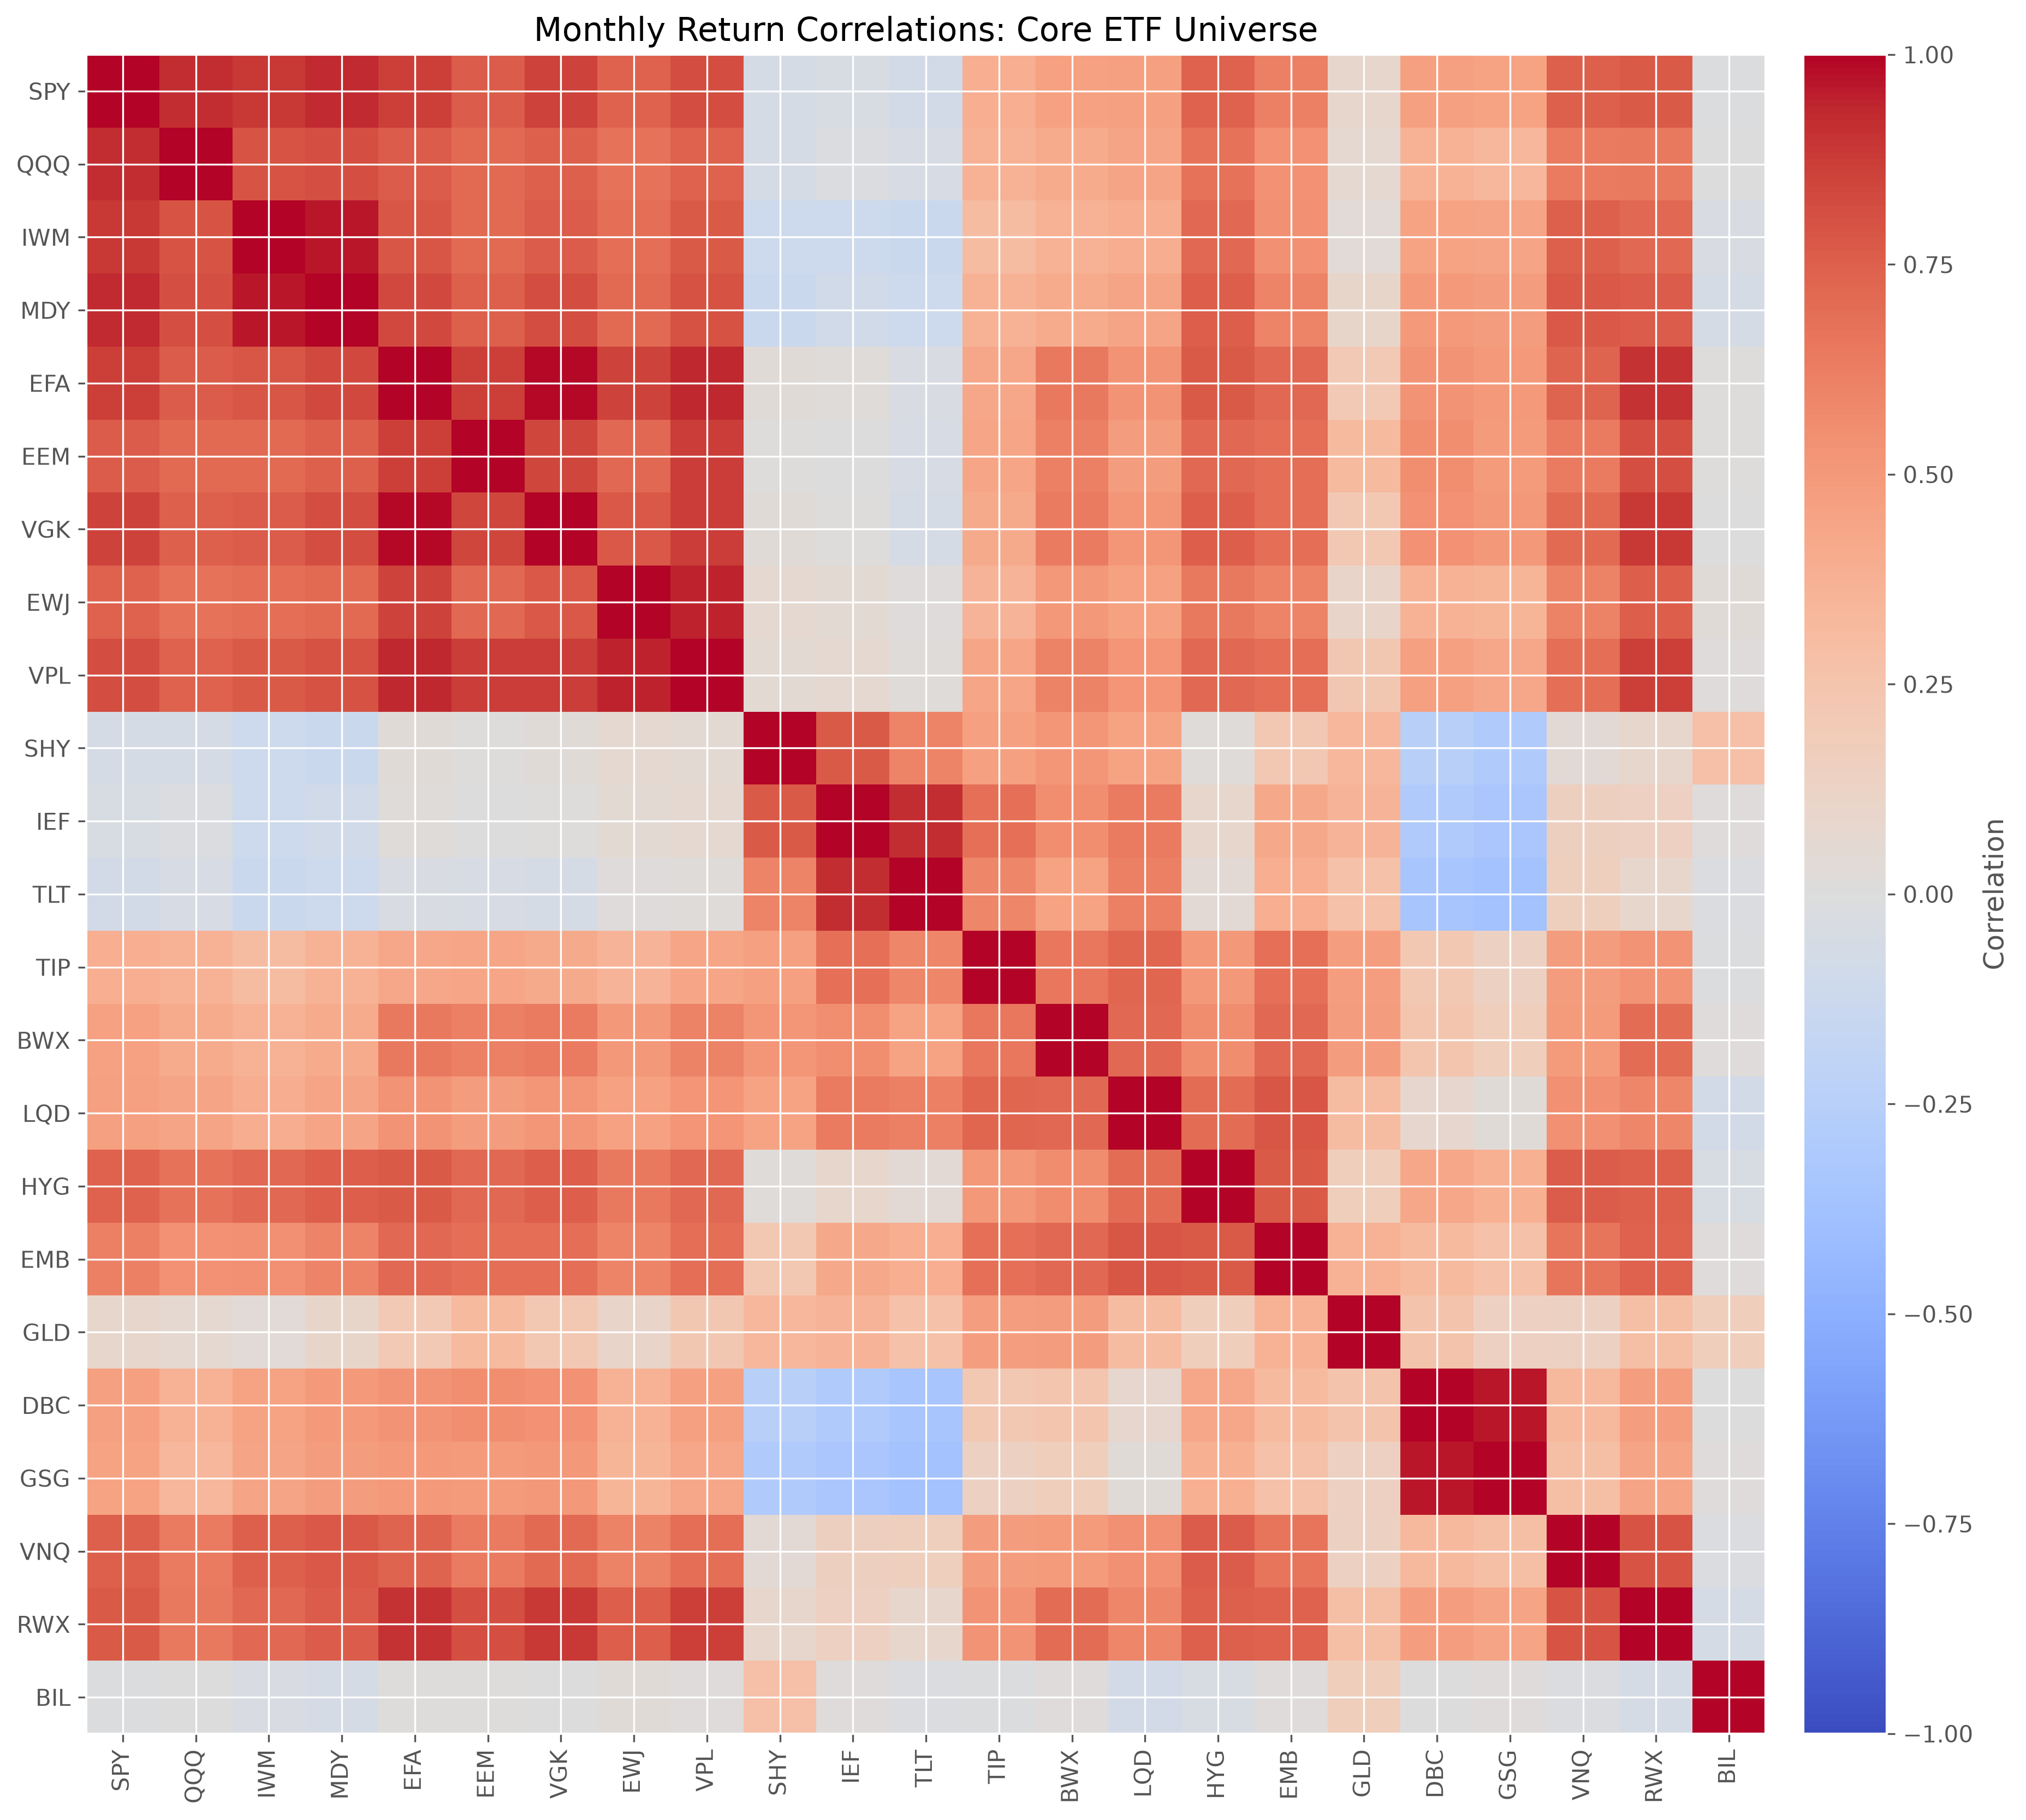

In [7]:
display(Image(filename=str(PROJECT_ROOT / 'outputs/figures/correlation_heatmap_core.png')))

## Diversification comments

The correlation matrix is a map of historical co-movement rather than a guarantee of future diversification. Equity ETFs form a relatively correlated cluster, while government bonds, commodities, real estate, credit, and cash introduce different risk sensitivities. Low or negative correlations can improve portfolio diversification, but they may change materially across crises and monetary regimes.

The sample covariance matrix is the direct historical estimate. Ledoit-Wolf shrinkage pulls noisy covariance estimates toward a structured target and is used as a more stable input in the optimized strategies. All rolling estimates use observations ending at t-1 so the rebalance-date return never enters its own portfolio decision.
